# 03 - Encoder: fine-tuned XLM-R

| Step | Details |
|---|---|
| Model | `xlm-roberta-base`, fine-tuned on a fixed subsample of the train part |
| Validation | fixed split from `common.split_train_val` (same rows as 02) |
| Long texts | one model, two inference modes: `truncate` (first 512 tokens) vs `chunks` (512-token windows, averaged) |
| Outputs | val / test probabilities in `outputs/`, confusion matrix, `submission_encoder.csv` |

- Kaggle: GPU T4 on, Internet on, competition data attached

## Setup

In [1]:
import os
import subprocess
import sys

from kaggle_secrets import UserSecretsClient

REPO = "https://github.com/mohinska/ai_hw3_AIGenTextDetection.git"
REPO_DIR = "/tmp/repo"

subprocess.run(["rm", "-rf", REPO_DIR], check=True)
subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, REPO_DIR], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")

# Hugging Face token from Kaggle Secrets (Add-ons -> Secrets -> HF_TOKEN): authenticated, faster model download
os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

In [2]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging
from tqdm.auto import tqdm

import common
from common import LABELS, TEXT_COL, LABEL_COL, SEED
from features import chunk_ids, mean_by_text

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")

device: cuda Tesla T4


## Config

In [3]:
MODEL_NAME = "xlm-roberta-base"
FINAL = True            # True: final run - whole train part, only the chunks mode
N_TRAIN = None if FINAL else 40_000   # stratified subsample of the train part
NAME = "encoder_full" if FINAL else "encoder"   # prefix of the saved probabilities / submission
MODES = ["chunks"] if FINAL else ["truncate", "chunks"]
MAX_LEN = 512
STRIDE = 64             # token overlap between neighbouring chunks
MAX_CHUNKS = 8          # chunks per text at inference: ~3.6k tokens, covers ~99% of texts
EPOCHS = 1
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 64
TEXT_BATCH = 5000        # texts tokenized at once (bounded RAM)
LR = 2e-5
WARMUP = 0.06           # share of steps with linear warmup
LOG_EVERY = 250         # print training loss every N steps

SUBMISSION_PATH = os.path.join(common.WORK_DIR, f"submission_{NAME}.csv")

## Data

In [4]:
train_df, test_df, sample_sub = common.load_data()
trn, val = common.split_train_val(train_df)
trn = common.subsample(trn, N_TRAIN)
y_val = val[LABEL_COL].to_numpy()
L2I = {l: i for i, l in enumerate(LABELS)}
print(f"train part: {len(trn):,} | val: {len(val):,} | test: {len(test_df):,}")

train part: 245,116 | val: 27,236 | test: 25,000


## Training

- Train texts are truncated to the first `MAX_LEN` tokens
- AdamW + linear schedule with warmup, fp16 on GPU, gradient clipping 1.0

In [5]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
collate = DataCollatorWithPadding(tok)


def encode_truncated(texts):
    """First MAX_LEN tokens of each text as int32 arrays. Tokenized in batches and cut to MAX_LEN * 12
    characters first (far beyond MAX_LEN tokens, same result): tokenizing 245k full texts at once ran out of RAM."""
    out = []
    for s in range(0, len(texts), TEXT_BATCH):
        part = [t[:MAX_LEN * 12] for t in texts[s:s + TEXT_BATCH]]
        ids = tok(part, truncation=True, max_length=MAX_LEN, return_attention_mask=False)["input_ids"]
        out += [np.array(x, dtype=np.int32) for x in ids]
    return out


def collate_train(items):
    """Pad a batch of (token ids, label) pairs."""
    batch = collate([{"input_ids": ids.tolist()} for ids, _ in items])
    batch["labels"] = torch.tensor([label for _, label in items])
    return batch


train_ids = encode_truncated(trn[TEXT_COL].fillna("").tolist())
train_items = list(zip(train_ids, trn[LABEL_COL].map(L2I)))
loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_train,
                    generator=torch.Generator().manual_seed(SEED))
print(f"{len(loader):,} steps per epoch")

15,320 steps per epoch


In [6]:
def train_epoch(model, loader, opt, sched, scaler):
    """One epoch of fp16 training with gradient clipping; returns the loss of every step."""
    model.train()
    losses = []
    for batch in tqdm(loader, desc="train", mininterval=60):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            loss = model(**batch).loss
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        losses.append(loss.item())
    return losses


model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(LABELS)).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(loader)
sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

t0 = time.time()
losses = [loss for _ in range(EPOCHS) for loss in train_epoch(model, loader, opt, sched, scaler)]
print(f"training: {(time.time() - t0) / 60:.1f} min")

step 250/15320 | loss 1.0131 | 2.2 min
step 500/15320 | loss 0.6062 | 4.5 min
step 750/15320 | loss 0.4656 | 6.7 min
step 1000/15320 | loss 0.4286 | 9.0 min
step 1250/15320 | loss 0.4359 | 11.2 min
step 1500/15320 | loss 0.3984 | 13.5 min
step 1750/15320 | loss 0.3751 | 15.7 min
step 2000/15320 | loss 0.3592 | 18.0 min
step 2250/15320 | loss 0.3301 | 20.2 min
step 2500/15320 | loss 0.3165 | 22.4 min
step 2750/15320 | loss 0.3304 | 24.7 min
step 3000/15320 | loss 0.3329 | 26.9 min
step 3250/15320 | loss 0.3108 | 29.1 min
step 3500/15320 | loss 0.3098 | 31.3 min
step 3750/15320 | loss 0.2678 | 33.5 min
step 4000/15320 | loss 0.2706 | 35.8 min
step 4250/15320 | loss 0.2659 | 38.0 min
step 4500/15320 | loss 0.2634 | 40.2 min
step 4750/15320 | loss 0.2631 | 42.4 min
step 5000/15320 | loss 0.2537 | 44.6 min
step 5250/15320 | loss 0.2497 | 46.8 min
step 5500/15320 | loss 0.2492 | 49.1 min
step 5750/15320 | loss 0.2596 | 51.3 min
step 6000/15320 | loss 0.2469 | 53.5 min
step 6250/15320 | loss 

In [ ]:
# mean training loss per LOG_EVERY steps
pd.Series(losses).groupby(np.arange(len(losses)) // LOG_EVERY).mean().round(4).rename("loss").to_frame()

## Inference: truncate vs chunks

| Mode | What the model sees |
|---|---|
| `truncate` | first 512 tokens |
| `chunks` | up to `MAX_CHUNKS` windows of 512 tokens with `STRIDE` overlap; class probabilities averaged per text |

In [7]:
@torch.no_grad()
def predict(ids_list):
    """Class probabilities for tokenized sequences (sorted by length for fast padding)."""
    model.eval()
    order = np.argsort([len(x) for x in ids_list])
    probs = np.zeros((len(ids_list), len(LABELS)), dtype=np.float32)
    for s in range(0, len(order), EVAL_BATCH_SIZE):
        idx = order[s:s + EVAL_BATCH_SIZE]
        batch = collate([{"input_ids": ids_list[i]} for i in idx])
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        probs[idx] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    return probs


def predict_texts(texts, mode):
    """Class probabilities per text: first MAX_LEN tokens ("truncate") or averaged chunks ("chunks")."""
    texts = texts.fillna("").tolist()
    if mode == "truncate":
        return predict([x.tolist() for x in encode_truncated(texts)])
    probs = []
    for s in range(0, len(texts), TEXT_BATCH):   # batches of texts: bounded RAM for the chunk tokenization
        part = texts[s:s + TEXT_BATCH]
        ids, text_idx = chunk_ids(part, tok, MAX_LEN, STRIDE, MAX_CHUNKS)
        probs.append(mean_by_text(predict(ids), text_idx, len(part)))
    return np.concatenate(probs)


def to_labels(proba):
    """Most probable label per row."""
    return np.array(LABELS)[proba.argmax(1)]


def scores(name, proba):
    """Macro-F1 and per-class F1 on the validation split."""
    pred = to_labels(proba)
    per_class = f1_score(y_val, pred, labels=LABELS, average=None)
    return {"model": name, "macro_f1": f1_score(y_val, pred, average="macro"),
            **{f"f1_{l}": f for l, f in zip(LABELS, per_class)}}

In [8]:
val_proba, minutes = {}, {}
for mode in MODES:
    t0 = time.time()
    val_proba[mode] = predict_texts(val[TEXT_COL], mode)
    common.save_proba(val["id"], val_proba[mode], LABELS, f"{NAME}_{mode}", "val")
    minutes[mode] = round((time.time() - t0) / 60, 1)
pd.Series(minutes, name="inference_min").to_frame()

chunks: 7.1 min


## Results on the validation split

- Baseline row appears if the output of 02 is attached as Kaggle input

In [9]:
rows = [scores(f"{NAME}_{m}", p) for m, p in val_proba.items()]
for path in common.find_outputs("val_proba_baseline.csv")[:1]:
    rows.append(scores("baseline_tfidf (02)", common.load_proba(path, val["id"])))
results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).round(4).reset_index(drop=True)
results.to_csv(os.path.join(common.WORK_DIR, "outputs", "encoder_results.csv"), index=False)
results

,model,macro_f1,f1_human,f1_ai,f1_fusion
0,encoder_full_chunks,0.8727,0.8147,0.9621,0.8413


In [10]:
BEST_MODE = max(val_proba, key=lambda m: f1_score(y_val, to_labels(val_proba[m]), average="macro"))
val_pred = to_labels(val_proba[BEST_MODE])
print("best mode:", BEST_MODE, "\n")
print(classification_report(y_val, val_pred, labels=LABELS, digits=4))

best mode: chunks 

              precision    recall  f1-score   support

       human     0.9205    0.7307    0.8147      6673
          ai     0.9907    0.9351    0.9621     12195
      fusion     0.7582    0.9449    0.8413      8368

    accuracy                         0.8881     27236
   macro avg     0.8898    0.8703    0.8727     27236
weighted avg     0.9021    0.8881    0.8889     27236



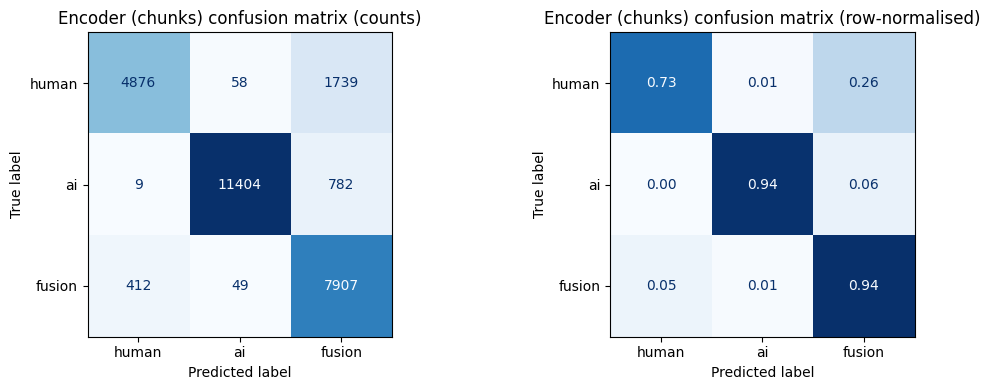

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, norm, title in zip(axes, [None, "true"], ["counts", "row-normalised"]):
    ConfusionMatrixDisplay.from_predictions(y_val, val_pred, labels=LABELS, normalize=norm,
                                            values_format=".2f" if norm else "d",
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Encoder ({BEST_MODE}) confusion matrix ({title})")
common.save_fig("encoder_cm.png")

In [12]:
# macro-F1 per domain for both modes: where chunking helps
pd.concat({m: common.f1_by(y_val, to_labels(p), val["domain"])["macro_f1"] for m, p in val_proba.items()},
          axis=1).assign(n=val["domain"].value_counts()).sort_values("n", ascending=False)

,chunks,n
g,,
student_essays,0.9318,5433
bundestag,0.8641,5229
cnn_news,0.9457,4360
blog_authorship_corpus,0.8781,4022
house_of_commons,0.8200,3229
euro_court_cases,0.7988,2757
arxiv_papers,0.4009,1428
gutenberg,0.7116,778


## Test predictions and submission

In [13]:
test_proba = predict_texts(test_df[TEXT_COL], BEST_MODE)
common.save_proba(test_df["id"], test_proba, LABELS, f"{NAME}_{BEST_MODE}", "test")
submission = common.save_submission(test_df["id"], to_labels(test_proba), sample_sub, SUBMISSION_PATH)
print("saved", SUBMISSION_PATH, submission.shape)
submission["label"].value_counts(normalize=True).round(3)

saved /kaggle/working/submission_encoder_full.csv (25000, 2)


label
ai        0.482
fusion    0.310
human     0.208
Name: proportion, dtype: float64

## Conclusions

Experiment run (`FINAL = False`, 40k texts, outputs replaced by the final run):

- **Chunks vs truncate:** `chunks` 0.8530 vs `truncate` 0.8353 (+0.018) -> reading the whole text helps; biggest gains on long-text domains: `gutenberg` +0.090, `euro_court_cases` +0.044, `bundestag` +0.032
- **Encoder vs baseline:** 0.8530 vs 0.8724 -> 40k texts, 1 epoch is not enough to beat TF-IDF; loss still falling at the end (0.30) -> more data / epochs should help
- **LB:** 0.84822 vs val 0.8530
- **`arxiv_papers` collapses:** 0.47 (`chunks`) vs 0.85 for the baseline -> the encoder does not see text length, which separates `ai` there (hypothesis)
- **Different errors than the baseline:** `human` recall 0.71 (often predicted as `fusion`), baseline has the opposite bias (`fusion` recall 0.79) -> good candidate for the ensemble in `05`
- **Encoder wins** on `student_essays` (0.911 vs 0.896) and `blog_authorship_corpus` (0.777 vs 0.752)

Final run (`FINAL = True`, 245k texts, `chunks` only, outputs above; run on the code before the refactor, same logic):

- **More data:** val macro-F1 0.8727 vs 0.8530 on 40k (+0.020); loss at the end 0.19 vs 0.30
- **Over-predicts `fusion`:** recall `fusion` 0.94 vs `human` 0.73 -> fixed by per-class scaling in `05`
- **Domains:** `blog_authorship_corpus` 0.88 (TF-IDF 0.76), but `arxiv_papers` still collapses (0.40) -> the two models complement each other